In [ ]:
pip install xgboost


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb
import numpy as np
import matplotlib.pyplot as plt
import time

In [ ]:
# Load dataset
df = pd.read_csv("StudentPerformanceFactors.csv")


In [ ]:
# Set target column
target = "Exam_Score"

In [ ]:
# Encode categorical columns
df = pd.get_dummies(df, drop_first=True)

In [ ]:
# Split features/target
X = df.drop(columns=[target]).values
y = df[target].values

In [ ]:
# Train/Val/Test split (60/20/20)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

In [ ]:
# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [ ]:
# Build XGBoost model
start_time = time.time()

model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=3000,
    learning_rate=0.02,
    max_depth=4,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    early_stopping_rounds=100
)

In [ ]:
# Train model
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.85, device=None, early_stopping_rounds=100,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.02, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=3000,
             n_jobs=None, num_parallel_tree=None, ...)

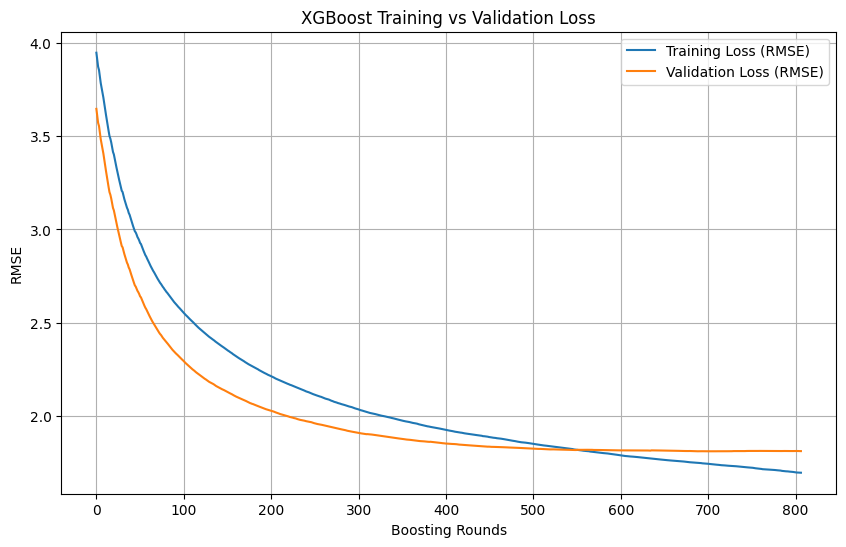

In [ ]:
# Extract training history
results = model.evals_result()

train_loss = results["validation_0"]["rmse"]
val_loss = results["validation_1"]["rmse"]

# Plot training vs validation loss
plt.figure(figsize=(10,6))
plt.plot(train_loss, label="Training Loss (RMSE)")
plt.plot(val_loss, label="Validation Loss (RMSE)")
plt.xlabel("Boosting Rounds")
plt.ylabel("RMSE")
plt.title("XGBoost Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predict on test set
y_pred = model.predict(X_test)

In [ ]:
# Evaluate
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R²:", r2)


Test MSE: 4.299038887023926
Test RMSE: 2.0734123774647255
Test R²: 0.7005536556243896
